# Primeiro trablho da disciplina de Análise Numérica
## Título: Similaridade de vetores em um espaço semântico
14/09/26

In [1]:
"""
Bibliotecas
"""
import numpy as np
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
)

/run/media/victors/Dados/Doutorado_disciplinas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4880.43it/s]


In [2]:
"""
Definindo a função x(t) e f(t) e funções auxiliares
"""

# Definindo a norma Euclidiana
def norma2(vetor):
    return np.sqrt(np.sum(vetor**2))

# Definindo a reta vetor1 -> vetor2
def X(t, vetor1, vetor2):
    return (1-t)*vetor1 + t*vetor2

# Definindo a função f por cosseno do angulo entre os vetores cos(x(t), c) e cos(x(t), d)
def f(t,a,b,c, d):
    x = X(t,a,b)
    return (x/norma2(x))@(c/norma2(c) - d/norma2(d)) # aqui ele faz o produto interno sum(a_i*b_i)

def cosseno(u,v):
   return np.dot(u,v)/(np.linalg.norm(u)*np.linalg.norm(v))

In [3]:
palavras = [
    "Matemática",
    "Português",
    "Ciência",
    "Humanidade"
]

embeddings = model.encode(palavras)

a = embeddings[0]
b = embeddings[1]
c = embeddings[2]
d = embeddings[3]

# verificando se tem raiz dentro da função
start = f(0, a,b,c,d)
end   = f(1, a,b,c,d)

### Gráficos da Função escolhida

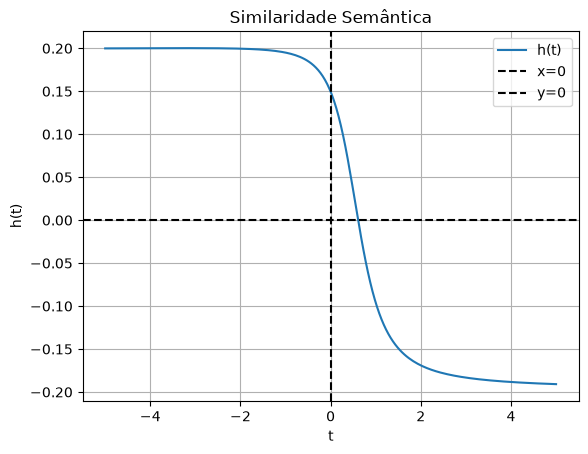

<Figure size 640x480 with 0 Axes>

In [22]:
t_valores = np.linspace(-5,5,200)
f_valores = [f(t,a,b,c,d) for t in t_valores]

plt.plot(t_valores,f_valores, label="h(t)")
plt.axhline(0, linestyle="--", color = 'black', label="x=0")
plt.axvline(0, linestyle="--", color = 'black', label="y=0")
plt.legend()

plt.xlabel("t")
plt.ylabel("h(t)")
plt.title("Similaridade Semântica")

plt.grid()
plt.show()
plt.savefig("figuras/similaridade_semantica.png", bbox_inches='tight')

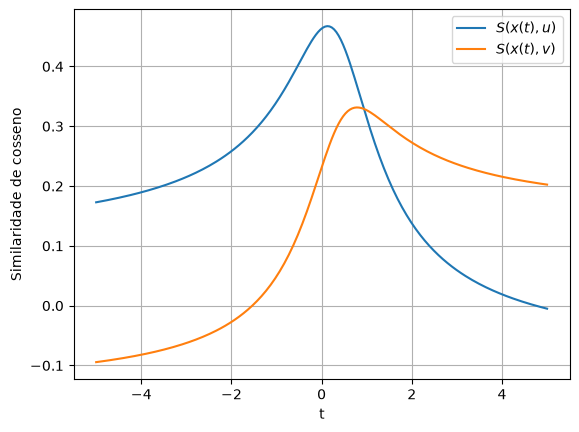

In [23]:
sim_a=[]
sim_b=[]

for t in t_valores:
    xt = X(t,c,d)

    sim_a.append(cosseno(xt,a))
    sim_b.append(cosseno(xt,b))

plt.plot(t_valores, sim_a, label=r"$S(x(t),u)$")
plt.plot(t_valores, sim_b, label=r"$S(x(t),v)$")

plt.xlabel("t")
plt.ylabel("Similaridade de cosseno")
plt.legend()
plt.grid()
plt.show()

### Para o método MIL é necessário verificar se |\phi(t)'| <1 para todo t \in [0,1].

In [4]:
# Método de Método interativo linear ()

q = b-a
v = (c/norma2(c) - d/norma2(d))

def phi(t):
  return t + (X(t,a,b)/(norma2(X(t,a,b))))@v


# def phi(x):
#   return (1 + v@((q/norma2(X(x,a,b))) - (X(x,a,b)*(np.dot(X(x,a,b),q)))/(norma2(X(x,a,b))**3)))

def mil(x0, Ep):
  x1 = phi(x0)
  k = 1
  pontos = [(x0, x1)]  # Inicializa a lista de pontos com o primeiro valor
  while np.abs(x1 - x0) > Ep:
    x0 = x1
    x1 = phi(x0)
    pontos.append((x0, x1))
    k +=1
  return float(x1), k, pontos

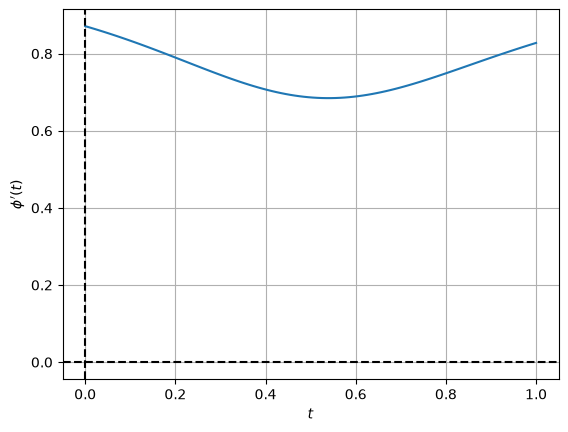

0.8712081901846569


In [ ]:
# Gráfico da derivada de \phi escolhida para o M.I.L


def phi_linha(t):
    return 1 + v@((q/norma2(X(t,a,b))) - (X(t,a,b)*(np.dot(X(t,a,b),q)))/(norma2(X(t,a,b))**3))
# def phi(t):
#     return t + (X(t,a,b)/(norma2(X(t,a,b))))@v
# np.dot(q,v)/norma2(X(t,a,b)) - (np.dot(X(t,a,b),q)*np.dot(X(t,a,b),v))/(norma2(X(t,a,b)))**3

x_valores = np.linspace(0,1,100)
phi_linha_valores = [phi_linha(x) for x in x_valores]

plt.plot(x_valores, phi_linha_valores)
plt.xlabel(r"$t$")
plt.ylabel(r"$\phi'(t)$")
plt.axhline(0, linestyle="--", color = 'black')
plt.axvline(0, linestyle="--", color = 'black')
# plt.legend()
plt.grid()
plt.show()
print(np.max(phi_linha_valores))

In [14]:
# Aplicando o método M.I.L
x0 = 0.5
Ep = 1e-8
x_star, k, pontos = mil(x0, Ep)
print(f"x*: {f(x_star,a,b,c,d)}, k: {k}")
print(f'x_star = {x_star:.12f}')


x*: 2.468004822731018e-08, k: 39
x_star = 0.610689342022


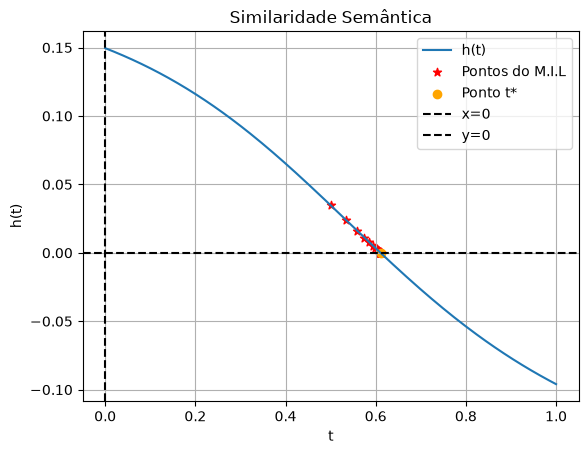

In [15]:
# Plot dos pontos do método M.I.L
x_pontos = [pontos[i][0] for i in range(len(pontos))]
y_pontos = [pontos[i][1] for i in range(len(pontos))]

f_pontos_y = [f(x_pontos[i],a,b,c,d) for i in range(len(y_pontos))]
t_valores = np.linspace(0,1,200)
f_valores = [f(t,a,b,c,d) for t in t_valores]

plt.plot(t_valores,f_valores, label="h(t)")
plt.scatter(x_pontos,f_pontos_y,marker='*', color = "red", label="Pontos do M.I.L")
plt.scatter(x_star, f(x_star,a,b,c,d),marker="o", color = "orange", label="Ponto t*")
plt.axhline(0, linestyle="--", color = 'black', label="x=0")
plt.axvline(0, linestyle="--", color = 'black', label="y=0")


plt.xlabel("t")
plt.ylabel("h(t)")
plt.title("Similaridade Semântica")

plt.legend()
plt.grid()
plt.show()

In [6]:
# calculando a raiz exata
t = np.dot(a,v)/np.dot(a-b,v)
print(t)

0.6106894


### Aplicando o método da Bissecção para achar o t*

In [11]:
# Método da Bissecção
def bissec(a0, b0, Ep, a, b, c, d):
    def valor(t):
        return f(t, a, b, c, d)

    fa = valor(a0)
    fb = valor(b0)

    if fa * fb > 0:
        raise ValueError("Não há mudança de sinal no intervalo.")

    pontos = []
    x_anterior = None
    k=0
    while True:
        x = (a0 + b0) / 2
        fx = valor(x)

        pontos.append((x, fx))

        if fx == 0:
            return x, pontos, k

        if x_anterior is not None:
            erro = abs(x - x_anterior)
            if erro <= Ep:
                return x, pontos,k

        if fa * fx < 0:
            b0 = x
            fb = fx
        else:
            a0 = x
            fa = fx

        x_anterior = x
        k+=1

In [12]:
#calculando o k
k = (np.log(1) - np.log(1e-8))/np.log(2)
print(k)

26.5754247590989


In [13]:
t_star_bisec, pontos,k = bissec(0,1,1e-8,a,b,c,d)

In [17]:
x = f(t_star_bisec, a, b, c, d)
print(f't_star_bisec = {t_star_bisec:.12f}')

t_star_bisec = 0.610689438879


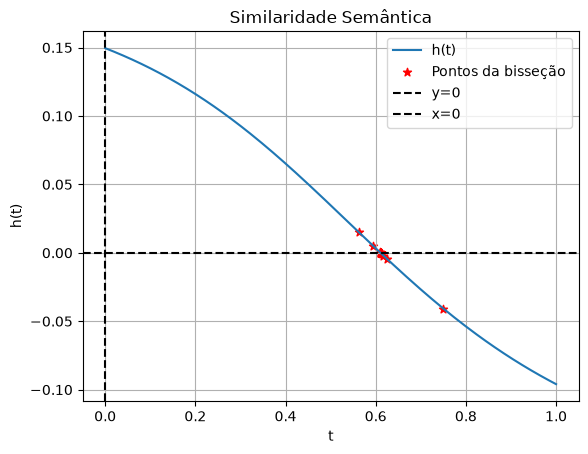

In [22]:
x_pontos = [pontos[i][0] for i in range(len(pontos))]
y_pontos = [pontos[i][1] for i in range(len(pontos))]

t_valores = np.linspace(0,1,200)
f_valores = [f(t,a,b,c,d) for t in t_valores]

plt.plot(t_valores,f_valores, label="h(t)")
plt.scatter(x_pontos,y_pontos,marker='*', color = "red", label="Pontos da bisseção")
# plt.scatter(t_star_mil, f(t_star_mil,a,b,c,d),marker="o", color = "orange", label="Ponto t*")
plt.axhline(0, linestyle="--", color = 'black', label="y=0")
plt.axvline(0, linestyle="--", color = 'black', label="x=0")


plt.xlabel("t")
plt.ylabel("h(t)")
plt.title("Similaridade Semântica")

plt.legend()
plt.grid()
plt.show()



### Método de Newton-Raphson (M.N.R.)

In [23]:
def derivadaf(t):
    q = b-a
    v = (c/norma2(c) - d/norma2(d))
    return v@((q/norma2(X(t,a,b))) - (X(t,a,b)*(np.dot(X(t,a,b),q)))/(norma2(X(t,a,b))**3))
def MNR(x0, Ep, epocas):
    x1 = x0 - f(x0,a,b,c,d)/derivadaf(x0)
    k = 0
    pontos_mnr = [(x0, x1)]
    while np.abs(x0-x1) > Ep:
        x0 = x1
        x1 = x0 - f(x0,a,b,c,d)/derivadaf(x0)
        k+=1
        pontos_mnr.append((x0, x1))
        if k > epocas:
            break
    return x1, pontos_mnr, k
    

In [27]:
def MNR(x0, Ep, epocas):
    pontos_mnr = []

    for k in range(1, epocas + 1):
        
        fx = f(x0, a, b, c, d)
        dfx = derivadaf(x0)

        x1 = x0 - fx / dfx
        pontos_mnr.append((x0, x1))

        if abs(x1 - x0) <= Ep:
            return x1, pontos_mnr, k

        x0 = x1

In [28]:
a, b, c, d = np.asarray(embeddings[:4], dtype=np.float64)

x, pontos_mnr, k = MNR(0.5, 1e-8, 100)
print(f"t*: {x:.12f}", f"f(t*): {f(x, a, b, c, d):.19f}")
print("Resíduo:", abs(f(x, a, b, c, d)))
print(k)

t*: 0.610689374383 f(t*): 0.0000000000000000269
Resíduo: 2.688821387764051e-17
3


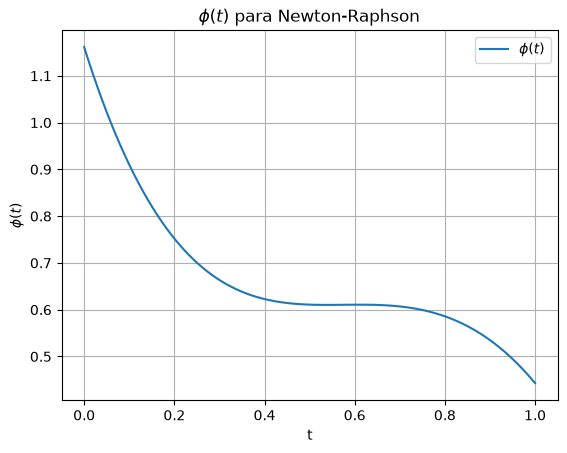

1.1612635276868153
0.4429672975260218


In [29]:
x = np.linspace(0,1,100)
y = [x_i - f(x_i,a,b,c,d)/derivadaf(x_i) for x_i in x]

plt.plot(x, y, label=r'$\phi(t)$')
plt.legend()
plt.xlabel('t')
plt.ylabel(r'$\phi(t)$')
plt.title(r'$\phi(t)$ para Newton-Raphson')
plt.grid(True)
plt.show()
print(np.max(y))
print(np.min(y))

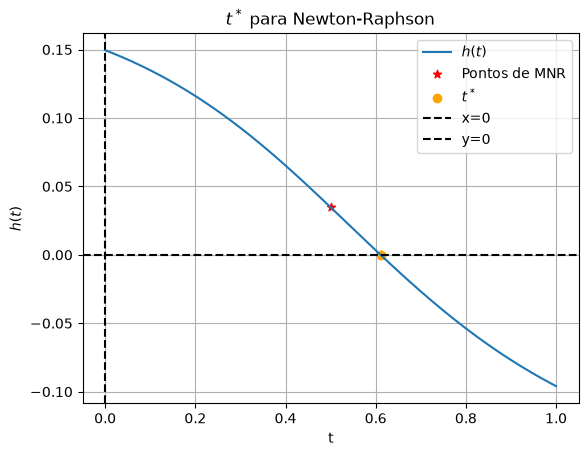

In [73]:
x_mnr = [pontos_mnr[i][0] for i in range(len(pontos_mnr))]
y_mnr = [pontos_mnr[i][1] for i in range(len(pontos_mnr))]
f_x_mnr = [f(x_mnr[i],a,b,c,d) for i in range(len(y_mnr))]
x_star_mnr = x
f_x_star_mnr = f(x_star_mnr, a, b, c, d)

plt.plot(t_valores, f_valores, label=r'$h(t)$')
plt.scatter(x_mnr, f_x_mnr, label=r'Pontos de MNR', marker='*', color='red')
plt.scatter(x_star_mnr, f_x_star_mnr, label=r'$t^*$', marker='o', color='orange')

plt.axhline(0, linestyle="--", color = 'black', label="x=0")
plt.axvline(0, linestyle="--", color = 'black', label="y=0")
plt.legend()
plt.xlabel('t')
plt.ylabel(r'$h(t)$')
plt.title(r'$t^*$ para Newton-Raphson')
plt.grid()
plt.show()

In [76]:
vex = X(t_star, a, b)
print(vex)

[ 1.87704389e-01  3.65682146e-02 -1.33128751e-01 -6.92246987e-03
 -3.00391583e-01 -7.78775661e-02  1.58159385e-01  2.94886148e-01
  3.51976502e-01  7.10902189e-02  1.09612799e-01 -3.02570339e-01
  1.77381481e-01  1.11549582e-01 -1.54652594e-01 -1.35113855e-01
 -1.75545484e-01  1.29508932e-01 -1.49883220e-01 -1.29219419e-01
  5.13354896e-01 -9.12898783e-02 -4.30035183e-01  3.59016419e-03
  2.41768091e-01  1.55534070e-01  3.87707937e-01  5.08522526e-02
 -3.63227415e-02 -2.87290538e-01  2.67638637e-01  1.16589818e-01
  5.35758112e-01 -9.76618164e-03 -9.03531425e-02 -6.18988111e-02
  2.39338287e-01 -9.61145914e-02  4.54679449e-01  3.92939942e-01
 -2.32423688e-01 -1.79710881e-01  7.57042640e-02  7.39557986e-02
  4.72082915e-01  4.23151455e-02  1.99981544e-01  1.14899632e-01
 -2.79419481e-02  1.31450732e-01  6.93116300e-02  1.62555885e-01
 -4.91185683e-01  2.13657012e-01 -5.06031776e-02 -3.81041678e-02
  3.30297387e-01  1.89692260e-01 -1.14677653e-01  3.04558457e-01
 -6.32437145e-03  3.71775

In [77]:
from wordfreq import top_n_list


In [78]:
palavras = top_n_list('pt', 5000)
print(len(palavras))
print(palavras[:10])

5000
['de', 'a', 'o', 'que', 'e', 'do', 'em', 'da', 'é', 'para']


In [ ]:
embeddings = model.encode(
    palavras)